In [1]:

# 1. Install gdown
!pip -q install gdown

# 2. Download your Google Drive ZIP file
import gdown
import os

file_id = "1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM"
zip_path = "/kaggle/working/dataset.zip"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, zip_path, quiet=False)

# 3. Verify the download
if os.path.exists(zip_path):
    print(f"Download complete: {zip_path}")
    print(f"File size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")
else:
    print("Download failed. Check the Drive sharing permissions.")


Downloading...
From (original): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM
From (redirected): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM&confirm=t&uuid=9106cf18-f7fd-4ea1-8dc2-857ef4d1be76
To: /kaggle/working/dataset.zip
100%|██████████| 804M/804M [00:07<00:00, 108MB/s]  

Download complete: /kaggle/working/dataset.zip
File size: 0.75 GB


In [2]:

import zipfile
import os

zip_path = "/kaggle/working/dataset.zip"
extract_path = "/kaggle/working/dataset"

if os.path.isfile(zip_path) and zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)
    print("Extracted to:", extract_path)
    print("Files:", os.listdir(extract_path)[:20])
else:
    print("ZIP file is missing, incomplete, or invalid.")


Extracted to: /kaggle/working/dataset
Files: ['noise_project_v2']


In [3]:

import os

folder = "/kaggle/working/dataset/noise_project_v2"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = "    " * (level + 1)
    for file in files[:20]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs.clear()


noise_project_v2/
    b6000_split.csv
    noisy_metadata_v2.csv
    clean_list.csv
    noise_manifest_v2.json
    noisy_500_v2/
        V/
            00002303_V_500_roll_02.png
            00002354_V_500_roll_01.png
            00002394_V_500_roll_08.png
            00002405_V_500_roll_07.png
            00002636_V_500_roll_01.png
            00002362_V_500_roll_06.png
            00002555_V_500_roll_05.png
            00002501_V_500_roll_04.png
            00002304_V_500_roll_04.png
            00002304_V_500_roll_01.png
            00002602_V_500_roll_01.png
            00002313_V_500_roll_04.png
            00002338_V_500_roll_08.png
            00002360_V_500_roll_05.png
            00002412_V_500_roll_05.png
            00002341_V_500_roll_06.png
            00002443_V_500_roll_07.png
            00002483_V_500_roll_06.png
            00002593_V_500_roll_01.png
            00002538_V_500_roll_02.png
        U/
            00002645_U_500_roll_02.png
            00002423_U_500_roll

In [4]:

from pathlib import Path
from collections import Counter

folder = Path("/kaggle/working/dataset/noise_project_v2")

files = [p for p in folder.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nFile types:")
print(Counter(p.suffix.lower() or "[no extension]" for p in files))

print("\nFirst 30 file paths:")
for p in files[:30]:
    print(p.relative_to(folder))


Total files: 4984

File types:
Counter({'.png': 4980, '.csv': 3, '.json': 1})

First 30 file paths:
b6000_split.csv
noisy_metadata_v2.csv
clean_list.csv
noise_manifest_v2.json
clean_500/V/00002303_V_500_roll_02.png
clean_500/V/00002354_V_500_roll_01.png
clean_500/V/00002394_V_500_roll_08.png
clean_500/V/00002405_V_500_roll_07.png
clean_500/V/00002636_V_500_roll_01.png
clean_500/V/00002362_V_500_roll_06.png
clean_500/V/00002555_V_500_roll_05.png
clean_500/V/00002501_V_500_roll_04.png
clean_500/V/00002304_V_500_roll_04.png
clean_500/V/00002304_V_500_roll_01.png
clean_500/V/00002602_V_500_roll_01.png
clean_500/V/00002313_V_500_roll_04.png
clean_500/V/00002338_V_500_roll_08.png
clean_500/V/00002360_V_500_roll_05.png
clean_500/V/00002412_V_500_roll_05.png
clean_500/V/00002341_V_500_roll_06.png
clean_500/V/00002443_V_500_roll_07.png
clean_500/V/00002483_V_500_roll_06.png
clean_500/V/00002593_V_500_roll_01.png
clean_500/V/00002538_V_500_roll_02.png
clean_500/V/00002351_V_500_roll_09.png
clean

In [5]:
import torch
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
!nvidia-smi
!pip -q list 2>/dev/null | grep -i -E "scikit-image|opencv|pandas|nbis"

torch: 2.11.0+cu128 | CUDA: True
Sat Oct 31 06:14:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------

In [6]:
import torch
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memory (GB):", round(torch.cuda.get_device_properties(0).total_memory/1e9, 1))

torch: 2.11.0+cu128 | CUDA: True
GPU: Tesla T4
Memory (GB): 15.6


In [7]:
import os, json, random
import numpy as np
import pandas as pd
import cv2
import torch

# ---------- Config ----------
ROOT = "/kaggle/working/dataset/noise_project_v2"
CLEAN_DIR = f"{ROOT}/clean_500"
NOISY_DIR = f"{ROOT}/noisy_500_v2"
SEED = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda:0")
print("Device:", torch.cuda.get_device_name(0))

# ---------- CSV inspection ----------
for name in ["b6000_split.csv", "clean_list.csv", "noisy_metadata_v2.csv"]:
    df = pd.read_csv(f"{ROOT}/{name}")
    print(f"\n=== {name} === shape: {df.shape}")
    print("Columns:", list(df.columns))
    print(df.head(3).to_string())

split_df = pd.read_csv(f"{ROOT}/b6000_split.csv")
for c in split_df.columns:
    if split_df[c].nunique() < 10:
        print(f"\nValue counts for '{c}':")
        print(split_df[c].value_counts())

# ---------- Manifest ----------
with open(f"{ROOT}/noise_manifest_v2.json") as f:
    manifest = json.load(f)
print("\nManifest top-level keys:", list(manifest.keys())[:15] if isinstance(manifest, dict) else type(manifest))

# ---------- Image shape check (ek pair, har folder se) ----------
for sub in ["U", "V", "S", "R"]:
    fname = sorted(os.listdir(f"{CLEAN_DIR}/{sub}"))[0]
    c = cv2.imread(f"{CLEAN_DIR}/{sub}/{fname}", cv2.IMREAD_UNCHANGED)
    n = cv2.imread(f"{NOISY_DIR}/{sub}/{fname}", cv2.IMREAD_UNCHANGED)
    print(f"\n[{sub}] {fname}")
    print("  clean:", c.shape, c.dtype, "min/max:", c.min(), c.max())
    print("  noisy:", n.shape, n.dtype, "min/max:", n.min(), n.max())

Device: Tesla T4

=== b6000_split.csv === shape: (6000, 30)
Columns: ['source', 'key', 'participant', 'device', 'ppi', 'capture', 'frgp', 'finger_name', 'zip_member', 'sha256', 'has_g_minutiae', 'sibling_1000_annotated', 'n_minutiae', 'g_irr_path', 'minutiae_mode', 'group_id', 'g_key', 'items_9_331_minutiae', 'items_9_320', 'items_9_321', 'items_9_325', 'items_9_326', 'has_class_9_307', 'class_9_307', 'has_annotation', 'nfiq2', 'valid', 'nfiq2_bin', 'quality_group', 'split']
  source                     key  participant device  ppi         capture  frgp finger_name                                                                  zip_member                                                            sha256  has_g_minutiae  sibling_1000_annotated  n_minutiae g_irr_path minutiae_mode    group_id                    g_key  items_9_331_minutiae  items_9_320  items_9_321  items_9_325  items_9_326 has_class_9_307 class_9_307  has_annotation  nfiq2  valid nfiq2_bin quality_group  split
0      b 

In [8]:
import pandas as pd
meta = pd.read_csv(f"{ROOT}/noisy_metadata_v2.csv")

meta["clean_path"] = meta.apply(lambda r: f"{CLEAN_DIR}/{r.device}/{r.key}.png", axis=1)
meta["noisy_path"] = meta.apply(lambda r: f"{NOISY_DIR}/{r.device}/{r.key}.png", axis=1)

print("Split counts:\n", meta["split"].value_counts())
print("Missing files:",
      sum(not os.path.isfile(p) for p in meta["clean_path"]),
      sum(not os.path.isfile(p) for p in meta["noisy_path"]))

# image size per device (har device ka ek sample nahi, 30 random)
sizes = {}
for dev, g in meta.groupby("device"):
    shp = [cv2.imread(p, 0).shape for p in g["clean_path"].sample(30, random_state=SEED)]
    sizes[dev] = pd.Series(shp).value_counts().head(3).to_dict()
print("\nSizes per device:", sizes)

print("\nNoise types (top 8):\n", meta["noises"].value_counts().head(8))

Split counts:
 split
train    1764
val       388
test      338
Name: count, dtype: int64
Missing files: 0 0

Sizes per device: {'R': {(429, 256): 1, (524, 384): 1, (422, 256): 1}, 'S': {(410, 256): 1, (462, 280): 1, (372, 256): 1}, 'U': {(750, 800): 30}, 'V': {(750, 800): 30}}

Noise types (top 8):
 noises
overink+creases                     73
overink                             68
creases+fragment+overink+partial    47
creases+fragment+overink            46
overink+gauss                       43
creases+fragment+overink+dots       38
overink+creases+partial             36
creases+fragment+overink+perlin     35
Name: count, dtype: int64


In [9]:
from torch.utils.data import Dataset, DataLoader

PATCH = 512
splits = {s: meta[meta["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
print({k: len(v) for k, v in splits.items()})

# Background value check (padding ke liye 255 sahi hai ya nahi)
def border_mean(p):
    im = cv2.imread(p, 0)
    return np.concatenate([im[0], im[-1], im[:, 0], im[:, -1]]).mean()

print("Mean border value per device (clean):")
for dev, g in meta.groupby("device"):
    print(dev, round(np.mean([border_mean(p) for p in g["clean_path"].sample(20, random_state=SEED)]), 1))

def pad_to(img, h, w, val=255):
    ph, pw = max(0, h - img.shape[0]), max(0, w - img.shape[1])
    return np.pad(img, ((0, ph), (0, pw)), constant_values=val)

class PairDS(Dataset):
    def __init__(self, df, train=True):
        self.df, self.train = df, train
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        n = cv2.imread(r.noisy_path, 0); c = cv2.imread(r.clean_path, 0)
        H0, W0 = c.shape
        if self.train:
            n, c = pad_to(n, PATCH, PATCH), pad_to(c, PATCH, PATCH)
            y = np.random.randint(0, n.shape[0] - PATCH + 1)
            x = np.random.randint(0, n.shape[1] - PATCH + 1)
            n, c = n[y:y+PATCH, x:x+PATCH], c[y:y+PATCH, x:x+PATCH]
        else:
            H, W = (H0 + 15) // 16 * 16, (W0 + 15) // 16 * 16
            n, c = pad_to(n, H, W), pad_to(c, H, W)
        f = lambda a: torch.from_numpy(a.astype(np.float32) / 127.5 - 1.0)[None]
        return f(n), f(c), r.key, (H0, W0)

train_dl = DataLoader(PairDS(splits["train"], True), batch_size=8, shuffle=True,
                      num_workers=2, pin_memory=True, drop_last=True)
val_dl   = DataLoader(PairDS(splits["val"], False),  batch_size=1, shuffle=False, num_workers=2)
test_dl  = DataLoader(PairDS(splits["test"], False), batch_size=1, shuffle=False, num_workers=2)

xb, yb, keys, _ = next(iter(train_dl))
print("train batch:", xb.shape, yb.shape, xb.min().item(), xb.max().item())
xv, yv, kv, orig = next(iter(val_dl))
print("val sample:", xv.shape, "original size:", orig)

{'train': 1764, 'val': 388, 'test': 338}
Mean border value per device (clean):
R 251.5
S 252.5
U 244.6
V 242.2
train batch: torch.Size([8, 1, 512, 512]) torch.Size([8, 1, 512, 512]) -1.0 1.0
val sample: torch.Size([1, 1, 448, 272]) original size: [tensor([440]), tensor([266])]


  0%|          | 0/2490 [00:00<?, ?it/s]

Saved: 2490
            mean       min       max
device                              
R       0.792703  0.597187  0.899885
S       0.803843  0.625503  0.920325
U       0.363115  0.139270  0.673243
V       0.362840  0.154695  0.666653


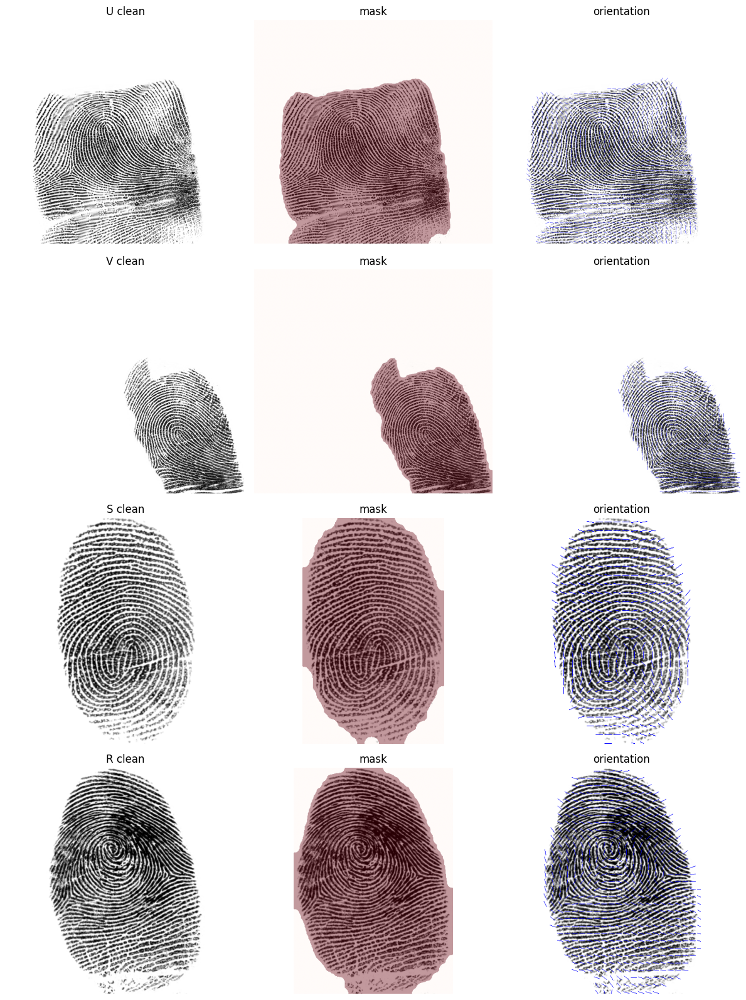

In [10]:
from tqdm.auto import tqdm
from scipy import ndimage as ndi
import matplotlib.pyplot as plt

LABEL_DIR = "/kaggle/working/labels"
os.makedirs(LABEL_DIR, exist_ok=True)
STRIDE = 4

def make_labels(gray, win=16, sigma=7, std_factor=0.6):
    img = gray.astype(np.float32) / 255.0
    h, w = img.shape

    # ---- orientation (structure tensor) ----
    sm = cv2.GaussianBlur(img, (0, 0), 1.0)
    gx = cv2.Sobel(sm, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(sm, cv2.CV_32F, 0, 1, ksize=3)
    gxx, gyy, gxy = [cv2.GaussianBlur(a, (0, 0), sigma) for a in (gx*gx, gy*gy, gx*gy)]
    hs, ws = (h + STRIDE - 1) // STRIDE, (w + STRIDE - 1) // STRIDE
    gxx, gyy, gxy = [cv2.resize(a, (ws, hs), interpolation=cv2.INTER_AREA) for a in (gxx, gyy, gxy)]
    theta = (0.5 * np.arctan2(2 * gxy, gxx - gyy) + np.pi / 2) % np.pi   # ridge direction

    # ---- segmentation (local std + Otsu) ----
    mean = cv2.blur(img, (win, win))
    var = np.maximum(cv2.blur(img * img, (win, win)) - mean ** 2, 0)
    std8 = np.clip(np.sqrt(var) / (np.sqrt(var).max() + 1e-6) * 255, 0, 255).astype(np.uint8)
    t, _ = cv2.threshold(std8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = (std8 > t * std_factor).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25)))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN,  cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11)))
    m = ndi.binary_fill_holes(m).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m)
    keep = np.zeros_like(m)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= 0.02 * h * w:
            keep[lab == i] = 1
    return keep, theta.astype(np.float16)

fg_frac = []
for _, r in tqdm(meta.iterrows(), total=len(meta)):
    out = f"{LABEL_DIR}/{r.key}.npz"
    if os.path.isfile(out):
        continue
    gray = cv2.imread(r.clean_path, 0)
    mask, ori = make_labels(gray)
    np.savez_compressed(out, mask=mask, ori=ori)
    fg_frac.append((r.device, mask.mean()))

print("Saved:", len(os.listdir(LABEL_DIR)))
print(pd.DataFrame(fg_frac, columns=["device", "fg"]).groupby("device")["fg"].describe()[["mean", "min", "max"]])

# ---- visual check: har device se ek sample ----
fig, ax = plt.subplots(4, 3, figsize=(12, 16))
for i, dev in enumerate(["U", "V", "S", "R"]):
    r = meta[(meta.device == dev) & (meta.split == "train")].iloc[0]
    gray = cv2.imread(r.clean_path, 0)
    d = np.load(f"{LABEL_DIR}/{r.key}.npz")
    mask, ori = d["mask"], d["ori"].astype(np.float32)
    ov = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    for yy in range(2, ori.shape[0], 4):
        for xx in range(2, ori.shape[1], 4):
            if mask[min(yy*STRIDE, mask.shape[0]-1), min(xx*STRIDE, mask.shape[1]-1)]:
                a = ori[yy, xx]; cx, cy = xx*STRIDE, yy*STRIDE
                dx, dy = int(7*np.cos(a)), int(-7*np.sin(a))
                cv2.line(ov, (cx-dx, cy-dy), (cx+dx, cy+dy), (255, 0, 0), 1)
    ax[i, 0].imshow(gray, cmap="gray"); ax[i, 0].set_title(f"{dev} clean")
    ax[i, 1].imshow(gray, cmap="gray"); ax[i, 1].imshow(mask, alpha=0.4, cmap="Reds"); ax[i, 1].set_title("mask")
    ax[i, 2].imshow(ov[..., ::-1]); ax[i, 2].set_title("orientation")
    for a_ in ax[i]: a_.axis("off")
plt.tight_layout(); plt.show()

U mean diff (deg): 3.7 | >20deg: 3.3 %
V mean diff (deg): 2.5 | >20deg: 1.1 %
S mean diff (deg): 2.4 | >20deg: 0.5 %
R mean diff (deg): 3.2 | >20deg: 1.9 %


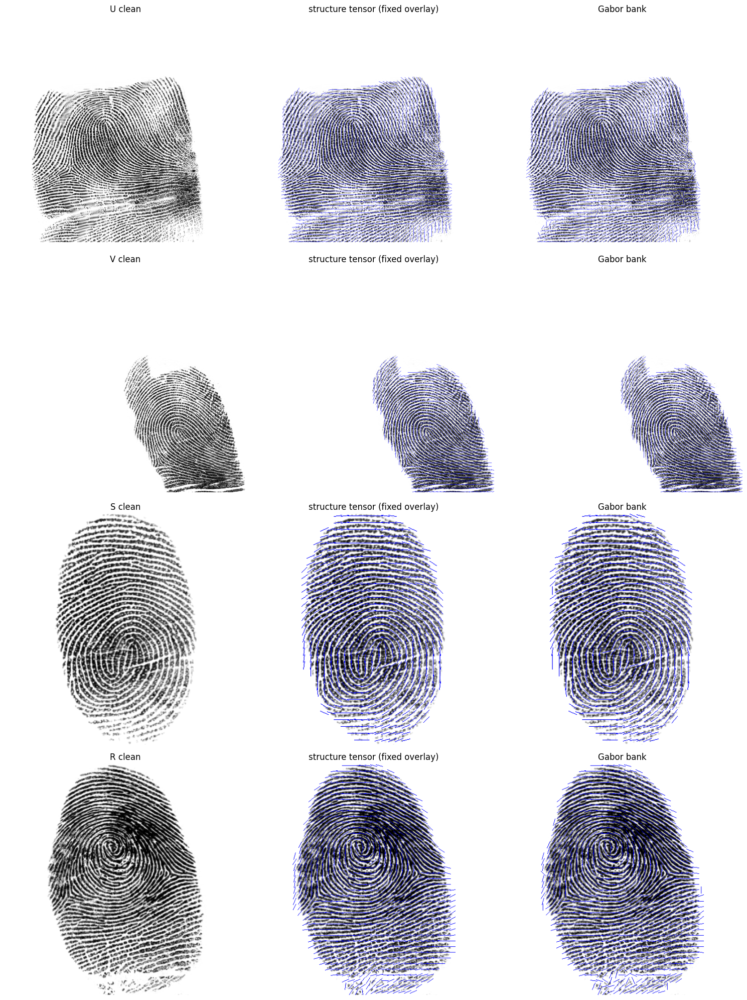

In [11]:
def ori_gabor(gray, n_ang=32, lambd=9.0, sigma=4.0, stride=4):
    img = 1.0 - gray.astype(np.float32) / 255.0
    img = img - cv2.GaussianBlur(img, (0, 0), 12)
    thetas = np.arange(n_ang) * np.pi / n_ang
    resp = []
    for t in thetas:
        k = cv2.getGaborKernel((31, 31), sigma, t, lambd, 1.0, 0, ktype=cv2.CV_32F)
        k -= k.mean()
        resp.append(cv2.GaussianBlur(np.abs(cv2.filter2D(img, cv2.CV_32F, k)), (0, 0), 3))
    ridge = (thetas[np.stack(resp).argmax(0)] + np.pi / 2) % np.pi
    c, s = [cv2.GaussianBlur(a, (0, 0), 4) for a in (np.cos(2 * ridge), np.sin(2 * ridge))]
    ridge = (0.5 * np.arctan2(s, c)) % np.pi
    return ridge[::stride, ::stride].astype(np.float32)

def draw_ori(gray, ori, mask, step=3, L=8):
    ov = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    for yy in range(1, ori.shape[0], step):
        for xx in range(1, ori.shape[1], step):
            cy, cx = yy * STRIDE, xx * STRIDE
            if cy < mask.shape[0] and cx < mask.shape[1] and mask[cy, cx]:
                a = ori[yy, xx]
                dx, dy = int(L * np.cos(a)), int(L * np.sin(a))   # y-down: +sin
                cv2.line(ov, (cx - dx, cy - dy), (cx + dx, cy + dy), (255, 0, 0), 1)
    return ov[..., ::-1]

def angdiff(a, b):
    d = np.abs(a - b) % np.pi
    return np.minimum(d, np.pi - d)

fig, ax = plt.subplots(4, 3, figsize=(15, 20))
for i, dev in enumerate(["U", "V", "S", "R"]):
    r = meta[(meta.device == dev) & (meta.split == "train")].iloc[0]
    gray = cv2.imread(r.clean_path, 0)
    d = np.load(f"{LABEL_DIR}/{r.key}.npz")
    mask, o_st = d["mask"], d["ori"].astype(np.float32)
    o_gb = ori_gabor(gray)
    h = min(o_st.shape[0], o_gb.shape[0]); w = min(o_st.shape[1], o_gb.shape[1])
    m4 = mask[::STRIDE, ::STRIDE][:h, :w] > 0
    dd = np.degrees(angdiff(o_st[:h, :w], o_gb[:h, :w])[m4])
    print(dev, "mean diff (deg):", round(dd.mean(), 1), "| >20deg:", round((dd > 20).mean() * 100, 1), "%")
    ax[i, 0].imshow(gray, cmap="gray"); ax[i, 0].set_title(f"{dev} clean")
    ax[i, 1].imshow(draw_ori(gray, o_st, mask)); ax[i, 1].set_title("structure tensor (fixed overlay)")
    ax[i, 2].imshow(draw_ori(gray, o_gb, mask)); ax[i, 2].set_title("Gabor bank")
    for a_ in ax[i]: a_.axis("off")
plt.tight_layout(); plt.show()

noisy torch.Size([8, 1, 512, 512]) | clean torch.Size([8, 1, 512, 512]) | mask torch.Size([8, 1, 512, 512]) | ori torch.Size([8, 1, 128, 128]) | ori prob torch.Size([8, 30, 128, 128])
prob sum ok: True | fg fraction in crops: 0.58


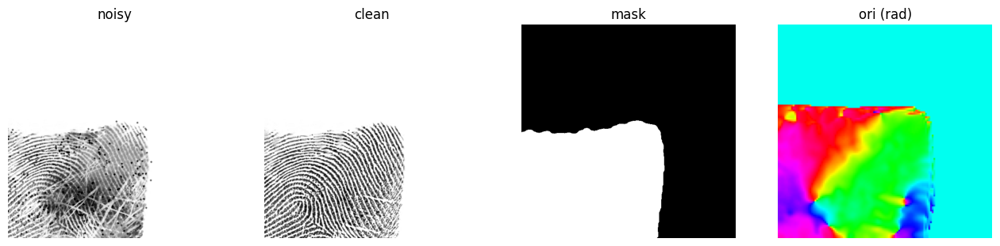

In [12]:
K_BINS, SIG_BINS = 30, 1.5

def ori_to_prob(ang, K=K_BINS, sig=SIG_BINS):
    # ang: (B,1,h,w) in [0, pi) -> (B,K,h,w) soft label, circular distance
    centers = torch.arange(K, device=ang.device).view(1, K, 1, 1) * (np.pi / K)
    d = torch.abs(ang - centers)
    d = torch.minimum(d, np.pi - d) / (np.pi / K)          # bins mein distance
    p = torch.exp(-0.5 * (d / sig) ** 2)
    return p / p.sum(1, keepdim=True)

class PairDS(Dataset):
    def __init__(self, df, train=True, fg_center=True):
        self.df, self.train, self.fg_center = df, train, fg_center
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        n = cv2.imread(r.noisy_path, 0); c = cv2.imread(r.clean_path, 0)
        d = np.load(f"{LABEL_DIR}/{r.key}.npz")
        m, o = d["mask"], d["ori"].astype(np.float32)
        H0, W0 = c.shape
        if self.train:
            Hp, Wp = max(H0, PATCH), max(W0, PATCH)
            n, c, m = pad_to(n, Hp, Wp), pad_to(c, Hp, Wp), pad_to(m, Hp, Wp, 0)
            o = pad_to(o, (Hp + 3) // 4, (Wp + 3) // 4, 0)
            ys, xs = np.nonzero(m)
            if self.fg_center and len(ys):
                k = np.random.randint(len(ys)); cy, cx = ys[k], xs[k]
                y = int(np.clip(cy - PATCH // 2, 0, Hp - PATCH)) // 4 * 4
                x = int(np.clip(cx - PATCH // 2, 0, Wp - PATCH)) // 4 * 4
            else:
                y = np.random.randint(0, (Hp - PATCH) // 4 + 1) * 4
                x = np.random.randint(0, (Wp - PATCH) // 4 + 1) * 4
            n, c, m = [a[y:y+PATCH, x:x+PATCH] for a in (n, c, m)]
            o = o[y//4:y//4 + PATCH//4, x//4:x//4 + PATCH//4]
        else:
            H, W = (H0 + 15) // 16 * 16, (W0 + 15) // 16 * 16
            n, c, m = pad_to(n, H, W), pad_to(c, H, W), pad_to(m, H, W, 0)
            o = pad_to(o, H // 4, W // 4, 0)
        f = lambda a: torch.from_numpy(a.astype(np.float32) / 127.5 - 1.0)[None]
        return (f(n), f(c), torch.from_numpy(m.astype(np.float32))[None],
                torch.from_numpy(o)[None], r.key, (H0, W0))

def make_train_dl(fg_center):
    return DataLoader(PairDS(splits["train"], True, fg_center), batch_size=8, shuffle=True,
                      num_workers=2, pin_memory=True, drop_last=True)

train_dl = make_train_dl(fg_center=True)      # warm-up ke liye
val_dl   = DataLoader(PairDS(splits["val"], False),  batch_size=1, num_workers=2)
test_dl  = DataLoader(PairDS(splits["test"], False), batch_size=1, num_workers=2)

xb, yb, mb, ob, _, _ = next(iter(train_dl))
pb = ori_to_prob(ob)
print("noisy", xb.shape, "| clean", yb.shape, "| mask", mb.shape, "| ori", ob.shape, "| ori prob", pb.shape)
print("prob sum ok:", torch.allclose(pb.sum(1), torch.ones_like(pb.sum(1)), atol=1e-4),
      "| fg fraction in crops:", round(mb.mean().item(), 2))

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a_, im, t in zip(ax, [xb[0, 0], yb[0, 0], mb[0, 0], ob[0, 0]], ["noisy", "clean", "mask", "ori (rad)"]):
    a_.imshow(im, cmap="gray" if t != "ori (rad)" else "hsv"); a_.set_title(t); a_.axis("off")
plt.show()

In [13]:
import torch.nn as nn, torch.nn.functional as F

def cbr(i, o, k=3, s=1, d=1):
    return nn.Sequential(nn.Conv2d(i, o, k, s, padding=d * (k // 2), dilation=d, bias=False),
                         nn.InstanceNorm2d(o, affine=True), nn.ReLU(True))

class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.b = nn.Sequential(nn.Conv2d(c, c, 3, 1, 1, bias=False), nn.InstanceNorm2d(c, affine=True), nn.ReLU(True),
                               nn.Conv2d(c, c, 3, 1, 1, bias=False), nn.InstanceNorm2d(c, affine=True))
    def forward(self, x): return F.relu(x + self.b(x))

class ASPP(nn.Module):
    def __init__(self, c, rates=(2, 4, 8)):
        super().__init__()
        self.br = nn.ModuleList([cbr(c, c // 2, 3, 1, r) for r in rates])
        self.fuse = cbr(c // 2 * len(rates), c, 1)
    def forward(self, x): return self.fuse(torch.cat([b(x) for b in self.br], 1))

def head(c, out):
    return nn.Sequential(cbr(c, 64), cbr(64, 32), nn.Conv2d(32, out, 1))

class Generator(nn.Module):
    def __init__(self, K=K_BINS, C=128, n_res=6):
        super().__init__()
        self.encoder = nn.Sequential(cbr(1, 32, 7), cbr(32, 64, 3, 2), cbr(64, C, 3, 2),
                                     *[ResBlock(C) for _ in range(n_res)], ASPP(C))
        self.enh = nn.Sequential(
            nn.ConvTranspose2d(C, 64, 4, 2, 1, bias=False), nn.InstanceNorm2d(64, affine=True), nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False), nn.InstanceNorm2d(32, affine=True), nn.ReLU(True),
            nn.Conv2d(32, 1, 3, 1, 1), nn.Tanh())
        self.ori, self.seg, self.qua = head(C, K), head(C, 1), head(C, 1)
    def forward(self, x):
        f = self.encoder(x)
        return {"enh": self.enh(f), "ori": self.ori(f), "seg": self.seg(f), "qua": self.qua(f), "feat": f}

class PatchD(nn.Module):
    def __init__(self):
        super().__init__()
        def blk(i, o, s, norm=True):
            L = [nn.Conv2d(i, o, 4, s, 1)]
            if norm: L.append(nn.InstanceNorm2d(o, affine=True))
            return L + [nn.LeakyReLU(0.2, True)]
        self.net = nn.Sequential(*blk(1, 64, 2, False), *blk(64, 128, 2), *blk(128, 256, 2), *blk(256, 512, 1),
                                 nn.Conv2d(512, 1, 4, 1, 1))
    def forward(self, x): return self.net(x)

G, D = Generator().to(device), PatchD().to(device)
npar = lambda m: sum(p.numel() for p in m.parameters())
print(f"G params: {npar(G)/1e6:.2f}M (~{npar(G)*4/1e6:.1f} MB fp32) | D params: {npar(D)/1e6:.2f}M")

xb, yb, mb, ob, _, _ = next(iter(train_dl))
with torch.no_grad():
    out = G(xb.to(device))
print({k: tuple(v.shape) for k, v in out.items()})
print("D out:", tuple(D(out["enh"]).shape), "| label ori:", tuple(ob.shape), "| mask:", tuple(mb.shape))
print("GPU mem (GB):", round(torch.cuda.max_memory_allocated() / 1e9, 2))

G params: 2.56M (~10.2 MB fp32) | D params: 2.76M
{'enh': (8, 1, 512, 512), 'ori': (8, 30, 128, 128), 'seg': (8, 1, 128, 128), 'qua': (8, 1, 128, 128), 'feat': (8, 128, 128, 128)}
D out: (8, 1, 62, 62) | label ori: (8, 1, 128, 128) | mask: (8, 1, 512, 512)
GPU mem (GB): 0.63


In [14]:
import time

LAM = dict(l1=100.0, ori=1.0, seg=1.0, qua=1.0)   # paper nahi deta: mere choices
LR, BETAS = 2e-4, (0.5, 0.999)
CKPT = "/kaggle/working/checkpoints"; os.makedirs(CKPT, exist_ok=True)

# ---------- helpers ----------
def down_mask(m):  return (F.avg_pool2d(m, 4) > 0.5).float()      # stride-4 binary mask
def masked_mean(x, m): return (x * m).sum() / m.sum().clamp(min=1.0)

# ---------- losses ----------
def d_loss(real, fake):                       # Eq.2, LSGAN (D side)
    return ((D(real) - 1) ** 2).mean() + (D(fake.detach()) ** 2).mean()
def g_adv(fake):                              # Eq.2, LSGAN (G side)
    return ((D(fake) - 1) ** 2).mean()
def loss_l1(enh, clean, m):                   # Eq.3 masked L1
    return masked_mean((enh - clean).abs(), m)
def loss_ori(logits, prob, m4):               # Eq.4, 5 masked CE
    return masked_mean(-(prob * F.log_softmax(logits, 1)).sum(1, keepdim=True), m4)
def loss_seg(logit, m4soft):                  # Eq.6 dice
    p = torch.sigmoid(logit)
    return 1 - 2 * (p * m4soft).sum() / (p.sum() + m4soft.sum() + 1e-6)
def quality_label(ori_logits, ori_ang):       # Eq.7
    o = ori_logits.argmax(1, keepdim=True).float() * (np.pi / K_BINS)   # estimated o in [0, pi)
    d = (o - ori_ang).abs()
    return torch.where(d <= np.pi / 2, torch.cos(d), torch.cos(np.pi - d))
def loss_qua(q_logit, qhat, m4):              # Eq.8 masked CE (soft target)
    return masked_mean(F.binary_cross_entropy_with_logits(q_logit, qhat, reduction="none"), m4)

# ---------- stage-wise freezing ----------
def trainable(stage):
    mods = {1: [G.encoder, G.enh],                    # warm-up: sirf enhancement
            2: [G.encoder, G.enh, G.ori, G.seg],      # cooperative
            3: [G.qua]}[stage]                        # quality
    for p in G.parameters(): p.requires_grad_(False)
    ps = []
    for mdl in mods:
        for p in mdl.parameters(): p.requires_grad_(True); ps.append(p)
    return ps

optD = torch.optim.Adam(D.parameters(), lr=LR, betas=BETAS)

def train_step(batch, stage, optG):
    x, y, m, ori = [t.to(device, non_blocking=True) for t in batch[:4]]
    ori = ori % np.pi
    m4, m4s = down_mask(m), F.avg_pool2d(m, 4)
    out = G(x); logs = {}
    if stage in (1, 2):                                   # D step
        optD.zero_grad(set_to_none=True)
        ld = d_loss(y, out["enh"]); ld.backward(); optD.step(); logs["D"] = ld.detach()
    optG.zero_grad(set_to_none=True)                      # G step
    if stage in (1, 2):
        la, l1 = g_adv(out["enh"]), loss_l1(out["enh"], y, m)
        loss = la + LAM["l1"] * l1; logs.update(adv=la.detach(), L1=l1.detach())
    if stage == 2:
        lo, ls = loss_ori(out["ori"], ori_to_prob(ori), m4), loss_seg(out["seg"], m4s)
        loss = loss + LAM["ori"] * lo + LAM["seg"] * ls; logs.update(ori=lo.detach(), seg=ls.detach())
    if stage == 3:
        with torch.no_grad(): qhat = quality_label(out["ori"], ori)
        lq = loss_qua(out["qua"], qhat, m4); loss = LAM["qua"] * lq; logs["qua"] = lq.detach()
    loss.backward(); optG.step()
    return logs

# ---------- validation (PSNR vs raw clean, original size) ----------
val_small = DataLoader(torch.utils.data.Subset(PairDS(splits["val"], False), list(range(0, len(splits["val"]), 6))),
                       batch_size=1, num_workers=2)
@torch.no_grad()
def val_psnr():
    G.eval(); ps = []
    for x, y, m, o, k, (h, w) in val_small:
        e = G(x.to(device))["enh"].cpu(); h, w = int(h), int(w)
        a = ((e[0, 0, :h, :w] + 1) * 127.5).clamp(0, 255).round()
        b = ((y[0, 0, :h, :w] + 1) * 127.5).round()
        ps.append(10 * np.log10(255 ** 2 / max(((a - b) ** 2).mean().item(), 1e-8)))
    G.train(); return float(np.mean(ps))

def load_ckpt(path):
    s = torch.load(path, map_location=device); G.load_state_dict(s["G"]); D.load_state_dict(s["D"]); print("loaded", path)

def run_stage(stage, epochs, fg_center, init=None):
    if init: load_ckpt(init)
    optG = torch.optim.Adam(trainable(stage), lr=LR, betas=BETAS)
    dl, best = make_train_dl(fg_center), -1.0
    G.train(); D.train()
    for ep in range(1, epochs + 1):
        t0, acc, n = time.time(), {}, 0
        for batch in dl:
            for k, v in train_step(batch, stage, optG).items(): acc[k] = acc.get(k, 0) + v
            n += 1
        msg = " ".join(f"{k}={float(v)/n:.4f}" for k, v in acc.items())
        vp = val_psnr() if stage < 3 else float("nan")
        print(f"[stage{stage}] ep {ep}/{epochs} | {msg} | val PSNR {vp:.2f} | {time.time()-t0:.0f}s")
        s = {"G": G.state_dict(), "D": D.state_dict(), "epoch": ep}
        torch.save(s, f"{CKPT}/stage{stage}_last.pt")
        if stage == 3 or vp > best:
            best = vp; torch.save(s, f"{CKPT}/stage{stage}_best.pt")

# ---------- sanity: ek batch par saare losses (no update) ----------
xb, yb, mb, ob, _, _ = [b for b in next(iter(train_dl))]
xb, yb, mb, ob = xb.to(device), yb.to(device), mb.to(device), ob.to(device) % np.pi
with torch.no_grad():
    o = G(xb); m4 = down_mask(mb)
    print("adv G/D:", g_adv(o["enh"]).item(), d_loss(yb, o["enh"]).item())
    print("L1:", loss_l1(o["enh"], yb, mb).item(), "| ori CE:", loss_ori(o["ori"], ori_to_prob(ob), m4).item(),
          "(log30=3.40)", "| dice:", loss_seg(o["seg"], F.avg_pool2d(mb, 4)).item())
    q = quality_label(o["ori"], ob); print("Qhat range:", q.min().item(), q.max().item(), "| qua loss:", loss_qua(o["qua"], q, m4).item())

adv G/D: 0.8284426927566528 1.001682162284851
L1: 0.7432025671005249 | ori CE: 3.50985050201416 (log30=3.40) | dice: 0.540520191192627
Qhat range: -4.371138828673793e-08 1.0 | qua loss: 0.7057799100875854


In [15]:
scalerG = torch.amp.GradScaler("cuda")
scalerD = torch.amp.GradScaler("cuda")
AC = lambda: torch.autocast("cuda", dtype=torch.float16)

def d_loss(real, fake):                       # Eq.2, LSGAN (D side), fp32 loss
    return ((D(real).float() - 1) ** 2).mean() + (D(fake.detach()).float() ** 2).mean()
def g_adv(fake):                              # Eq.2, LSGAN (G side), fp32 loss
    return ((D(fake).float() - 1) ** 2).mean()

def train_step(batch, stage, optG):
    x, y, m, ori = [t.to(device, non_blocking=True) for t in batch[:4]]
    ori = ori % np.pi
    m4, m4s = down_mask(m), F.avg_pool2d(m, 4)
    with AC():
        out = G(x)
    out = {k: v.float() for k, v in out.items() if k != "feat"}
    logs = {}
    if stage in (1, 2):                                   # D step
        optD.zero_grad(set_to_none=True)
        with AC():
            ld = d_loss(y, out["enh"])
        scalerD.scale(ld).backward(); scalerD.step(optD); scalerD.update(); logs["D"] = ld.detach()
    optG.zero_grad(set_to_none=True)                      # G step
    for p in D.parameters(): p.requires_grad_(False)
    if stage in (1, 2):
        with AC():
            la = g_adv(out["enh"])
        l1 = loss_l1(out["enh"], y, m)
        loss = la + LAM["l1"] * l1; logs.update(adv=la.detach(), L1=l1.detach())
    if stage == 2:
        lo, ls = loss_ori(out["ori"], ori_to_prob(ori), m4), loss_seg(out["seg"], m4s)
        loss = loss + LAM["ori"] * lo + LAM["seg"] * ls; logs.update(ori=lo.detach(), seg=ls.detach())
    if stage == 3:
        with torch.no_grad(): qhat = quality_label(out["ori"], ori)
        lq = loss_qua(out["qua"], qhat, m4); loss = LAM["qua"] * lq; logs["qua"] = lq.detach()
    scalerG.scale(loss).backward(); scalerG.step(optG); scalerG.update()
    for p in D.parameters(): p.requires_grad_(True)
    return logs

# ---- speed benchmark (G + D, AMP) ----
def bench_amp(n=30):
    xb, yb, mb, ob, _, _ = next(iter(train_dl))
    x, y, m = xb.to(device), yb.to(device), mb.to(device)
    sc = torch.amp.GradScaler("cuda")
    for i in range(n + 3):
        if i == 3: torch.cuda.synchronize(); t = time.time()
        with AC():
            out = G(x); la = g_adv(out["enh"].float())
        sc.scale(la + 100 * loss_l1(out["enh"].float(), y, m)).backward()
        G.zero_grad(set_to_none=True); D.zero_grad(set_to_none=True)
    torch.cuda.synchronize(); return n / (time.time() - t)

trainable(1)
print("GPU-only it/s with AMP:", round(bench_amp(), 2), "(PREVIOUS: 1.01)")

GPU-only it/s with AMP: 3.47 (PREVIOUS: 1.01)


In [17]:
run_stage(1, epochs=20, fg_center=True)

[stage1] ep 1/20 | D=0.4657 adv=0.5907 L1=0.3783 | val PSNR 12.50 | 94s
[stage1] ep 2/20 | D=0.3707 adv=0.5185 L1=0.3178 | val PSNR 15.11 | 93s
[stage1] ep 3/20 | D=0.4249 adv=0.4636 L1=0.3027 | val PSNR 15.80 | 93s
[stage1] ep 4/20 | D=0.5092 adv=0.4072 L1=0.2874 | val PSNR 15.72 | 93s
[stage1] ep 5/20 | D=0.4300 adv=0.4587 L1=0.2770 | val PSNR 16.34 | 93s
[stage1] ep 6/20 | D=0.2956 adv=0.6201 L1=0.2684 | val PSNR 16.27 | 93s
[stage1] ep 7/20 | D=0.2829 adv=0.6444 L1=0.2569 | val PSNR 16.00 | 93s
[stage1] ep 8/20 | D=0.2759 adv=0.6553 L1=0.2505 | val PSNR 16.70 | 93s
[stage1] ep 9/20 | D=0.2730 adv=0.6412 L1=0.2438 | val PSNR 17.00 | 93s
[stage1] ep 10/20 | D=0.2938 adv=0.6209 L1=0.2371 | val PSNR 17.46 | 93s
[stage1] ep 11/20 | D=0.2915 adv=0.6033 L1=0.2310 | val PSNR 17.23 | 93s
[stage1] ep 12/20 | D=0.2943 adv=0.5987 L1=0.2266 | val PSNR 17.10 | 93s
[stage1] ep 13/20 | D=0.3110 adv=0.5838 L1=0.2217 | val PSNR 17.40 | 93s
[stage1] ep 14/20 | D=0.3122 adv=0.5828 L1=0.2199 | val PSNR

In [18]:
ps = []
for x, y, m, o, k, (h, w) in val_small:
    h, w = int(h), int(w)
    a = ((x[0, 0, :h, :w] + 1) * 127.5).round(); b = ((y[0, 0, :h, :w] + 1) * 127.5).round()
    ps.append(10 * np.log10(255 ** 2 / max(((a - b) ** 2).mean().item(), 1e-8)))
print("noisy-input PSNR vs clean (val_small):", round(float(np.mean(ps)), 2))

noisy-input PSNR vs clean (val_small): 13.4


In [19]:
run_stage(2, epochs=60, fg_center=False, init=f"{CKPT}/stage1_best.pt")

loaded /kaggle/working/checkpoints/stage1_best.pt
[stage2] ep 1/60 | D=0.3436 adv=0.5538 L1=0.2081 ori=2.6946 seg=0.1997 | val PSNR 17.98 | 97s
[stage2] ep 2/60 | D=0.9636 adv=0.6420 L1=0.2047 ori=2.2958 seg=0.1161 | val PSNR 18.31 | 96s
[stage2] ep 3/60 | D=0.4102 adv=0.3853 L1=0.1984 ori=2.1667 seg=0.0782 | val PSNR 18.21 | 96s
[stage2] ep 4/60 | D=0.3609 adv=0.4695 L1=0.1981 ori=2.1052 seg=0.0573 | val PSNR 17.67 | 96s
[stage2] ep 5/60 | D=0.3501 adv=0.4956 L1=0.1973 ori=2.0747 seg=0.0454 | val PSNR 18.03 | 96s
[stage2] ep 6/60 | D=0.3373 adv=0.5159 L1=0.1955 ori=2.0507 seg=0.0366 | val PSNR 18.32 | 96s
[stage2] ep 7/60 | D=0.3341 adv=0.5147 L1=0.1945 ori=2.0401 seg=0.0309 | val PSNR 18.30 | 96s
[stage2] ep 8/60 | D=0.3595 adv=0.5075 L1=0.1939 ori=2.0282 seg=0.0276 | val PSNR 18.09 | 96s
[stage2] ep 9/60 | D=0.3436 adv=0.5110 L1=0.1927 ori=2.0198 seg=0.0247 | val PSNR 18.04 | 96s
[stage2] ep 10/60 | D=0.3368 adv=0.5117 L1=0.1905 ori=2.0113 seg=0.0222 | val PSNR 17.65 | 96s
[stage2] 

In [20]:
run_stage(3, epochs=5, fg_center=False, init=f"{CKPT}/stage2_best.pt")

loaded /kaggle/working/checkpoints/stage2_best.pt
[stage3] ep 1/5 | qua=0.1983 | val PSNR nan | 21s
[stage3] ep 2/5 | qua=0.1117 | val PSNR nan | 20s
[stage3] ep 3/5 | qua=0.0773 | val PSNR nan | 20s
[stage3] ep 4/5 | qua=0.0617 | val PSNR nan | 20s
[stage3] ep 5/5 | qua=0.0523 | val PSNR nan | 20s


loaded /kaggle/working/checkpoints/stage3_best.pt


  0%|          | 0/338 [00:00<?, ?it/s]

=== OVERALL (338 test images) ===
time_ms       31.545
psnr_noisy    13.288
ssim_noisy     0.672
rmse_noisy    57.600
psnr_enh      19.204
ssim_enh       0.864
rmse_enh      29.894
psnr_enhQ     20.386
ssim_enhQ      0.915
rmse_enhQ     25.704

=== PER DEVICE ===
device              R       S          U          V
time_ms     32.828000  24.637  34.598000  34.606000
psnr_noisy  11.091000  11.906  14.728000  14.652000
ssim_noisy   0.558000   0.586   0.766000   0.732000
rmse_noisy  72.445000  66.689  48.003000  48.489000
psnr_enh    17.959999  18.642  20.191999  19.500999
ssim_enh     0.869000   0.876   0.869000   0.840000
rmse_enh    33.400000  30.693  27.321000  29.685000
psnr_enhQ   17.959999  18.666  22.048000  22.021999
ssim_enhQ    0.870000   0.879   0.948000   0.949000
rmse_enhQ   33.410000  30.604  20.682000  20.817000


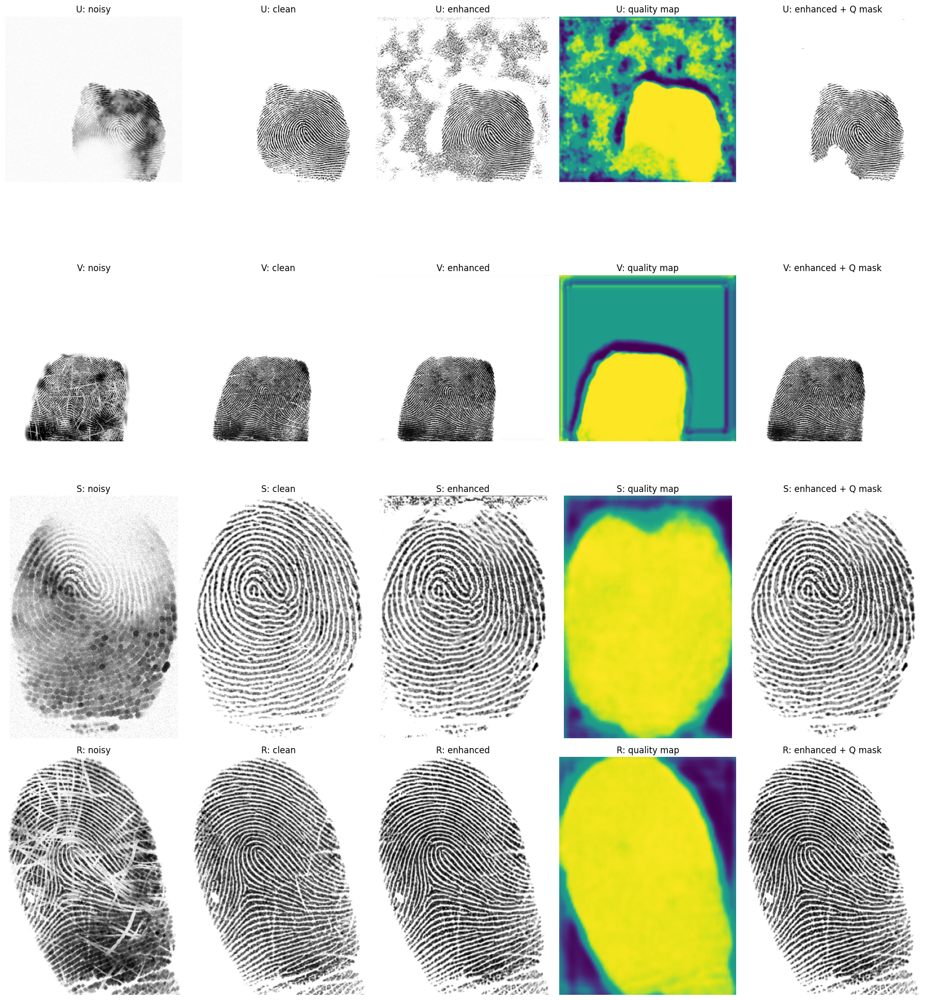

In [22]:
from skimage.metrics import structural_similarity as ssim_fn
import matplotlib.pyplot as plt

load_ckpt(f"{CKPT}/stage3_best.pt"); G.eval()
TAU = 0.5
OUT_DIR = "/kaggle/working/coogan_test_out"
for d_ in ["enh", "enh_q"]: os.makedirs(f"{OUT_DIR}/{d_}", exist_ok=True)
dev_of = dict(zip(meta.key, meta.device))
to8 = lambda t: ((t + 1) * 127.5).clamp(0, 255).round().byte().cpu().numpy()

@torch.no_grad()
def enhance(xd):
    with AC(): out = G(xd)
    enh = out["enh"].float()
    up = lambda t: F.interpolate(torch.sigmoid(t.float()), size=enh.shape[-2:], mode="bilinear", align_corners=False)
    q, seg = up(out["qua"]), up(out["seg"])
    keep = (seg > 0.5) & (q >= TAU)
    return enh, q, seg, torch.where(keep, enh, torch.ones_like(enh))

def metrics(a, b):
    mse = ((a.astype(np.float32) - b.astype(np.float32)) ** 2).mean()
    return 10 * np.log10(255 ** 2 / max(mse, 1e-8)), ssim_fn(b, a, data_range=255), float(np.sqrt(mse))

# warm-up (pehle call ka time kharab na ho)
xw = next(iter(test_dl))[0].to(device); enhance(xw); torch.cuda.synchronize()

rows = []
for x, y, m, o, key, (h, w) in tqdm(test_dl):
    h, w, key = int(h), int(w), key[0]
    xd = x.to(device)
    torch.cuda.synchronize(); t0 = time.time()
    enh, q, seg, enh_q = enhance(xd)
    torch.cuda.synchronize(); dt = (time.time() - t0) * 1000
    b, n = to8(y[0, 0, :h, :w]), to8(x[0, 0, :h, :w])
    a, aq = to8(enh[0, 0, :h, :w]), to8(enh_q[0, 0, :h, :w])
    cv2.imwrite(f"{OUT_DIR}/enh/{key}.png", a); cv2.imwrite(f"{OUT_DIR}/enh_q/{key}.png", aq)
    r = dict(key=key, device=dev_of[key], time_ms=dt)
    for tag, im in [("noisy", n), ("enh", a), ("enhQ", aq)]:
        r[f"psnr_{tag}"], r[f"ssim_{tag}"], r[f"rmse_{tag}"] = metrics(im, b)
    rows.append(r)

res = pd.DataFrame(rows); res.to_csv(f"{OUT_DIR}/test_metrics.csv", index=False)
cols = [c for c in res.columns if c not in ("key", "device")]
print("=== OVERALL (338 test images) ===");  print(res[cols].mean().round(3).to_string())
print("\n=== PER DEVICE ===");  print(res.groupby("device")[cols].mean().round(3).T.to_string())

# ---- visuals: har device se ek test sample ----
fig, ax = plt.subplots(4, 5, figsize=(18, 20))
for i, dev in enumerate(["U", "V", "S", "R"]):
    k = res[res.device == dev].key.iloc[0]; j = list(res.key).index(k)
    x, y, m, o, _, (h, w) = test_dl.dataset[j]; h, w = int(h), int(w)
    enh, q, seg, enh_q = enhance(x[None].to(device))
    for a_, im, t in zip(ax[i], [x[0], y[0], enh[0, 0].cpu(), q[0, 0].cpu(), enh_q[0, 0].cpu()],
                         ["noisy", "clean", "enhanced", "quality map", "enhanced + Q mask"]):
        a_.imshow(im[:h, :w], cmap="gray" if t != "quality map" else "viridis"); a_.set_title(f"{dev}: {t}"); a_.axis("off")
plt.tight_layout(); plt.show()

In [23]:
!pip install -q "nbis-python>=0.1.17"
import nbis
from nbis import NbisExtractorSettings

def make_ext(ppi):
    s = NbisExtractorSettings(min_quality=0.0, get_center=False, check_fingerprint=False,
                              compute_nfiq2=True, ppi=ppi)
    return nbis.new_nbis_extractor(s)
try:    ext = make_ext(500)
except Exception as ex:
    print("ppi=500 not accepted, using default:", ex); ext = make_ext(None)

def nfiq2_score(img):
    ok, buf = cv2.imencode(".png", img)
    try:    return float(ext.extract_minutiae(buf.tobytes()).quality().score)
    except Exception: return np.nan

te = splits["test"].set_index("key")
print("sanity (clean):", [nfiq2_score(cv2.imread(te.loc[k].clean_path, 0)) for k in res.key[:5]])

rows = []
for k in tqdm(res.key):
    r = te.loc[k]
    rows.append((nfiq2_score(cv2.imread(r.noisy_path, 0)),
                 nfiq2_score(cv2.imread(f"{OUT_DIR}/enh/{k}.png", 0)),
                 nfiq2_score(cv2.imread(f"{OUT_DIR}/enh_q/{k}.png", 0)),
                 nfiq2_score(cv2.imread(r.clean_path, 0))))
res[["nfiq2_noisy", "nfiq2_enh", "nfiq2_enhQ", "nfiq2_clean"]] = np.array(rows)
res.to_csv(f"{OUT_DIR}/test_metrics_with_nfiq2.csv", index=False)

def summ(d):
    t = pd.DataFrame({
        "Before (noisy)":  [d[f"{m}_noisy"].mean() for m in ("ssim", "psnr", "rmse", "nfiq2")],
        "COOGAN":          [d[f"{m}_enh"].mean()   for m in ("ssim", "psnr", "rmse", "nfiq2")],
        "COOGAN + Q mask": [d[f"{m}_enhQ"].mean()  for m in ("ssim", "psnr", "rmse", "nfiq2")]},
        index=["SSIM", "PSNR (dB)", "RMSE", "NFIQ2"])
    t["Change (COOGAN)"] = t["COOGAN"] - t["Before (noisy)"]
    return t.round(3)

print(f"Test images: {len(res)} | Avg enhancement time: {res.time_ms.mean()/1000:.4f} s/image")
display(summ(res))
print("Clean reference NFIQ2 mean:", round(res.nfiq2_clean.mean(), 2))
v = res.dropna(subset=["nfiq2_noisy", "nfiq2_enh"])
print(f"NFIQ2 improved on {(v.nfiq2_enh > v.nfiq2_noisy).sum()} of {len(v)} images")
print(f"SSIM improved on {(res.ssim_enh > res.ssim_noisy).sum()} of {len(res)} images")
print("NaN counts:", res[["nfiq2_noisy", "nfiq2_enh", "nfiq2_enhQ", "nfiq2_clean"]].isna().sum().to_dict())
for d in "UVSR":
    print(f"\nDevice {d} (n={(res.device == d).sum()})"); display(summ(res[res.device == d]))

sanity (clean): [81.0, 74.0, 65.0, 66.0, 66.0]


  0%|          | 0/338 [00:00<?, ?it/s]

Test images: 338 | Avg enhancement time: 0.0315 s/image


,Before (noisy),COOGAN,COOGAN + Q mask,Change (COOGAN)
SSIM,0.672,0.864,0.915,0.192
PSNR (dB),13.288,19.204,20.386,5.916
RMSE,57.600,29.894,25.704,-27.706
NFIQ2,20.083,67.852,71.902,47.769


Clean reference NFIQ2 mean: 71.77
NFIQ2 improved on 329 of 338 images
SSIM improved on 322 of 338 images
NaN counts: {'nfiq2_noisy': 0, 'nfiq2_enh': 0, 'nfiq2_enhQ': 0, 'nfiq2_clean': 0}

Device U (n=104)


,Before (noisy),COOGAN,COOGAN + Q mask,Change (COOGAN)
SSIM,0.766,0.869,0.948,0.103
PSNR (dB),14.728,20.192,22.048,5.465
RMSE,48.003,27.321,20.682,-20.682
NFIQ2,18.885,63.471,69.173,44.587


... (2 outputs left out)


Device S (n=93)


,Before (noisy),COOGAN,COOGAN + Q mask,Change (COOGAN)
SSIM,0.586,0.876,0.879,0.289
PSNR (dB),11.906,18.642,18.666,6.736
RMSE,66.689,30.693,30.604,-35.997
NFIQ2,20.247,74.849,74.452,54.602



Device R (n=60)


,Before (noisy),COOGAN,COOGAN + Q mask,Change (COOGAN)
SSIM,0.558,0.869,0.870,0.311
PSNR (dB),11.091,17.960,17.960,6.869
RMSE,72.445,33.400,33.410,-39.045
NFIQ2,16.350,72.983,73.433,56.633


In [24]:
@torch.no_grad()
def variants(xd, taus=(0.3, 0.5, 0.7)):
    with AC(): out = G(xd)
    enh = out["enh"].float()
    up = lambda t: F.interpolate(torch.sigmoid(t.float()), size=enh.shape[-2:], mode="bilinear", align_corners=False)
    q, seg = up(out["qua"]), up(out["seg"]); one = torch.ones_like(enh)
    v = {"1_raw": enh, "2_seg only": torch.where(seg > 0.5, enh, one),
         "5_Q0.5 only": torch.where(q >= 0.5, enh, one)}
    for t in taus: v[f"3_seg+Q{t}"] = torch.where((seg > 0.5) & (q >= t), enh, one)
    return v

rows = []
for x, y, m, o, key, (h, w) in tqdm(test_dl):
    h, w, key = int(h), int(w), key[0]; b = to8(y[0, 0, :h, :w])
    for name, t in variants(x.to(device)).items():
        p, s, r_ = metrics(to8(t[0, 0, :h, :w]), b)
        rows.append((name, dev_of[key], p, s, r_))
ab = pd.DataFrame(rows, columns=["variant", "device", "psnr", "ssim", "rmse"])
print(ab.groupby("variant")[["psnr", "ssim", "rmse"]].mean().round(3))
print(ab.groupby(["variant", "device"])[["psnr", "ssim"]].mean().round(3).unstack())

  0%|          | 0/338 [00:00<?, ?it/s]

                  psnr   ssim    rmse
variant                              
1_raw        19.204000  0.864  29.894
2_seg only   20.382000  0.915  25.710
3_seg+Q0.3   20.385000  0.915  25.705
3_seg+Q0.5   20.386000  0.915  25.704
3_seg+Q0.7   20.351999  0.914  25.844
5_Q0.5 only  19.370001  0.874  29.420
                  psnr                                    ssim                \
device               R          S          U          V      R      S      U   
variant                                                                        
1_raw        17.959999  18.642000  20.191999  19.500999  0.869  0.876  0.869   
2_seg only   17.959999  18.665001  22.038000  22.021999  0.870  0.878  0.948   
3_seg+Q0.3   17.959999  18.665001  22.048000  22.021999  0.870  0.878  0.948   
3_seg+Q0.5   17.959999  18.666000  22.048000  22.021999  0.870  0.879  0.948   
3_seg+Q0.7   17.896000  18.586000  22.048000  22.023001  0.869  0.876  0.948   
5_Q0.5 only  17.961000  18.676001  20.545000  19.702000 

In [25]:
vals = []
for x, y, m, o, key, (h, w) in tqdm(test_dl):
    h, w = int(h), int(w)
    v = variants(x.to(device))
    vals.append([nfiq2_score(to8(v[k][0, 0, :h, :w])) for k in ("2_seg only", "3_seg+Q0.5")])
vals = np.array(vals)
print("NFIQ2 | raw:", round(res.nfiq2_enh.mean(), 2),
      "| seg only:", round(np.nanmean(vals[:, 0]), 2),
      "| seg+Q0.5:", round(np.nanmean(vals[:, 1]), 2))

  0%|          | 0/338 [00:00<?, ?it/s]

NFIQ2 | raw: 67.85 | seg only: 71.96 | seg+Q0.5: 71.9


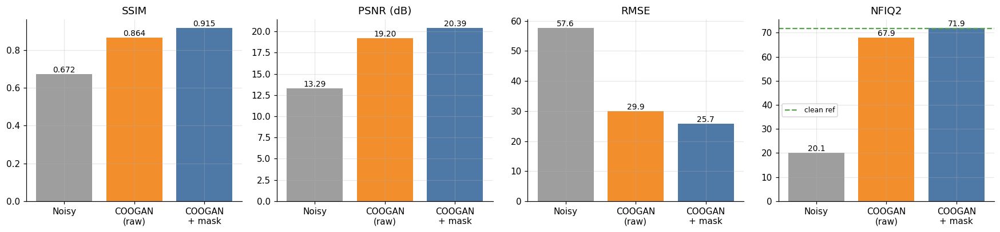

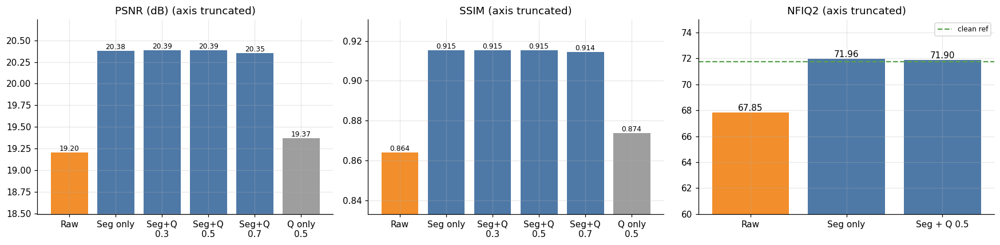

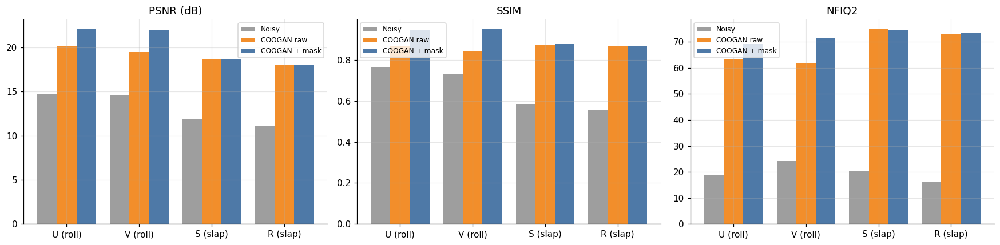

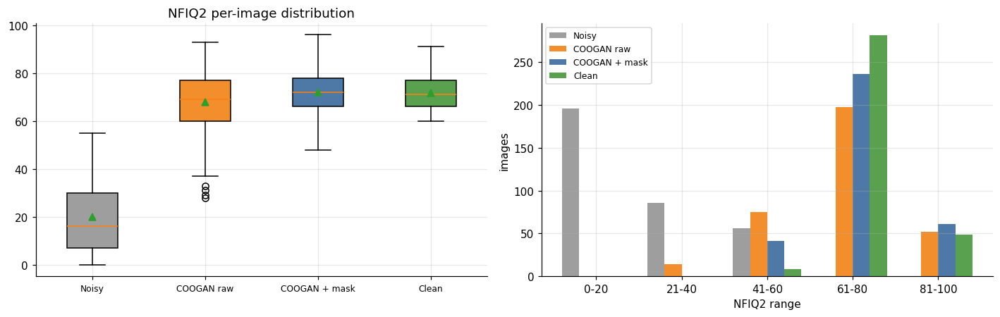

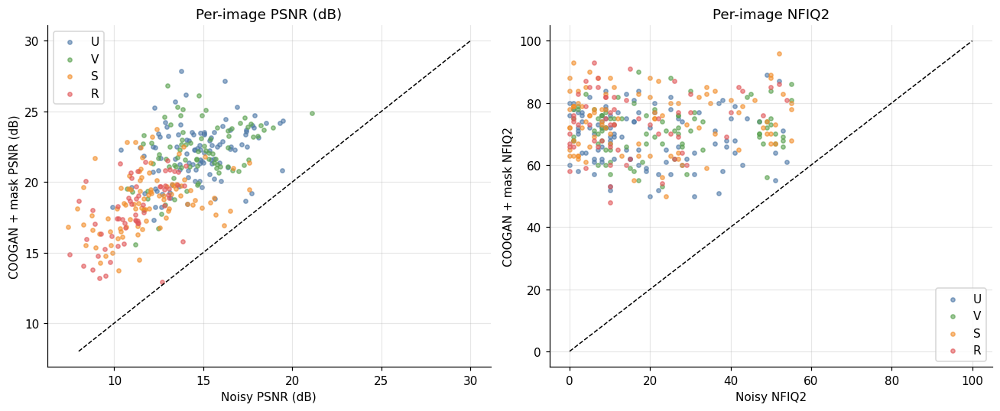

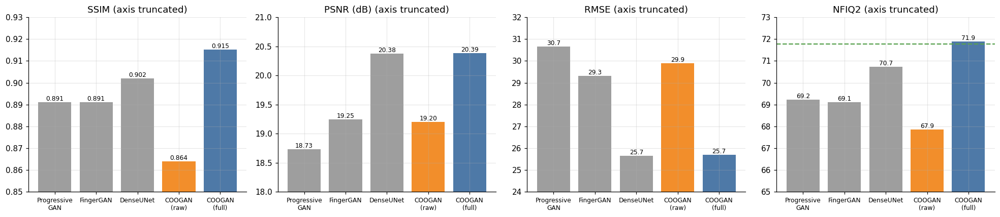

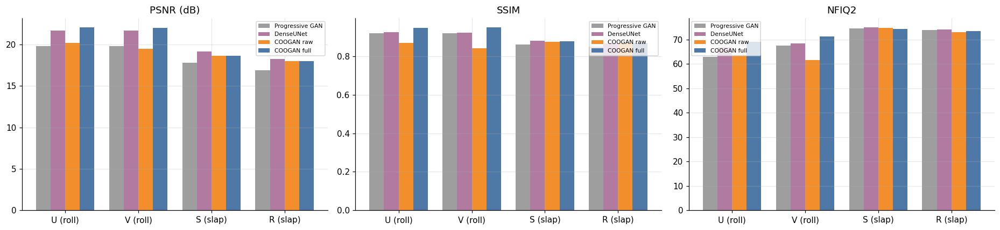

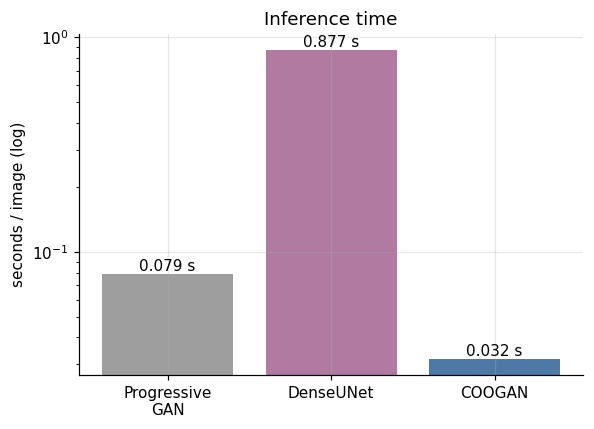

In [27]:
import matplotlib.pyplot as plt
GR = "/kaggle/working/coogan_graphs"; os.makedirs(GR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
C_N, C_R, C_E, C_C = "#9e9e9e", "#f28e2b", "#4e79a7", "#59a14f"
DEVS, DLAB = ["U", "V", "S", "R"], ["U (roll)", "V (roll)", "S (slap)", "R (slap)"]
def save(fig, name): fig.tight_layout(); fig.savefig(f"{GR}/{name}.png", dpi=200); plt.show()
FMT = dict(ssim="%.3f", psnr="%.2f", rmse="%.1f", nfiq2="%.1f")
METS = [("ssim", "SSIM"), ("psnr", "PSNR (dB)"), ("rmse", "RMSE"), ("nfiq2", "NFIQ2")]

# 1) Before / after
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, (k, t) in zip(ax, METS):
    v = [res[f"{k}_noisy"].mean(), res[f"{k}_enh"].mean(), res[f"{k}_enhQ"].mean()]
    a.bar_label(a.bar(["Noisy", "COOGAN\n(raw)", "COOGAN\n+ mask"], v, color=[C_N, C_R, C_E]), fmt=FMT[k], fontsize=9)
    a.set_title(t)
    if k == "nfiq2": a.axhline(res.nfiq2_clean.mean(), ls="--", c=C_C, label="clean ref"); a.legend(fontsize=8)
save(fig, "1_before_after")

# 2) Mask ablation (NFIQ2 seg-only value Cell 13 ke output se)
NF_SEG = 71.96
order = ["1_raw", "2_seg only", "3_seg+Q0.3", "3_seg+Q0.5", "3_seg+Q0.7", "5_Q0.5 only"]
lab = ["Raw", "Seg only", "Seg+Q\n0.3", "Seg+Q\n0.5", "Seg+Q\n0.7", "Q only\n0.5"]
m = ab.groupby("variant")[["psnr", "ssim"]].mean().loc[order]
colv = [C_R, C_E, C_E, C_E, C_E, C_N]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, k, t in zip(ax[:2], ["psnr", "ssim"], ["PSNR (dB)", "SSIM"]):
    pad = m[k].max() - m[k].min()
    a.bar_label(a.bar(lab, m[k], color=colv), fmt=FMT[k], fontsize=8)
    a.set_ylim(m[k].min() - .6 * pad, m[k].max() + .3 * pad); a.set_title(f"{t} (axis truncated)")
nf = [res.nfiq2_enh.mean(), NF_SEG, res.nfiq2_enhQ.mean()]
ax[2].bar_label(ax[2].bar(["Raw", "Seg only", "Seg + Q 0.5"], nf, color=[C_R, C_E, C_E]), fmt="%.2f")
ax[2].axhline(res.nfiq2_clean.mean(), ls="--", c=C_C, label="clean ref"); ax[2].legend(fontsize=8)
ax[2].set_ylim(60, 75); ax[2].set_title("NFIQ2 (axis truncated)")
save(fig, "2_mask_ablation")

# 3) Per-device
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (k, t) in zip(ax, [("psnr", "PSNR (dB)"), ("ssim", "SSIM"), ("nfiq2", "NFIQ2")]):
    g = res.groupby("device")[[f"{k}_noisy", f"{k}_enh", f"{k}_enhQ"]].mean().loc[DEVS]
    x = np.arange(4)
    for i, (c, l, col) in enumerate(zip(g.columns, ["Noisy", "COOGAN raw", "COOGAN + mask"], [C_N, C_R, C_E])):
        a.bar(x + (i - 1) * .27, g[c], .27, label=l, color=col)
    a.set_xticks(x); a.set_xticklabels(DLAB); a.set_title(t); a.legend(fontsize=8)
save(fig, "3_per_device")

# 4) NFIQ2 distribution
data = [res.nfiq2_noisy, res.nfiq2_enh, res.nfiq2_enhQ, res.nfiq2_clean]
names, cols = ["Noisy", "COOGAN raw", "COOGAN + mask", "Clean"], [C_N, C_R, C_E, C_C]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
bp = ax[0].boxplot(data, patch_artist=True, showmeans=True); ax[0].set_xticklabels(names, fontsize=8)
for p, c in zip(bp["boxes"], cols): p.set_facecolor(c)
ax[0].set_title("NFIQ2 per-image distribution")
bins, bn = [-1, 20, 40, 60, 80, 100], ["0-20", "21-40", "41-60", "61-80", "81-100"]
for i, (d, l, c) in enumerate(zip(data, names, cols)):
    ax[1].bar(np.arange(5) + (i - 1.5) * .2, pd.cut(d, bins, labels=bn).value_counts().reindex(bn).values, .2, label=l, color=c)
ax[1].set_xticks(range(5)); ax[1].set_xticklabels(bn); ax[1].set_xlabel("NFIQ2 range"); ax[1].set_ylabel("images"); ax[1].legend(fontsize=8)
save(fig, "4_nfiq2_distribution")

# 5) Per-image scatter (noisy vs enhanced + mask)
cd = dict(U="#4e79a7", V="#59a14f", S="#f28e2b", R="#e15759")
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for d in DEVS:
    s = res[res.device == d]
    ax[0].scatter(s.psnr_noisy, s.psnr_enhQ, s=12, alpha=.6, c=cd[d], label=d)
    ax[1].scatter(s.nfiq2_noisy, s.nfiq2_enhQ, s=12, alpha=.6, c=cd[d], label=d)
for a, t, lim in zip(ax, ["PSNR (dB)", "NFIQ2"], [(8, 30), (0, 100)]):
    a.plot(lim, lim, "k--", lw=1); a.set_xlabel(f"Noisy {t}"); a.set_ylabel(f"COOGAN + mask {t}"); a.set_title(f"Per-image {t}"); a.legend()
save(fig, "5_per_image_scatter")

# 6) Model comparison (baaki models ke numbers tumhare notebooks ke saved outputs se)
models = ["Progressive\nGAN", "FingerGAN", "DenseUNet", "COOGAN\n(raw)", "COOGAN\n(full)"]
V = dict(ssim=[.891, .891, .902, res.ssim_enh.mean(), res.ssim_enhQ.mean()],
         psnr=[18.729, 19.248, 20.377, res.psnr_enh.mean(), res.psnr_enhQ.mean()],
         rmse=[30.657, 29.309, 25.652, res.rmse_enh.mean(), res.rmse_enhQ.mean()],
         nfiq2=[69.219, 69.12, 70.734, res.nfiq2_enh.mean(), res.nfiq2_enhQ.mean()])
YL = dict(ssim=(.85, .93), psnr=(18, 21), rmse=(24, 32), nfiq2=(65, 73))
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, (k, t) in zip(ax, METS):
    a.bar_label(a.bar(models, V[k], color=[C_N, C_N, C_N, C_R, C_E]), fmt=FMT[k], fontsize=8)
    a.set_ylim(*YL[k]); a.set_title(f"{t} (axis truncated)"); a.tick_params(axis="x", labelsize=8)
    if k == "nfiq2": a.axhline(res.nfiq2_clean.mean(), ls="--", c=C_C)
save(fig, "6_model_comparison")

# 7) Per-device model comparison (U, V, S, R order)
OT = {"Progressive GAN": dict(psnr=[19.801, 19.798, 17.805, 16.861], ssim=[.920, .919, .862, .849], nfiq2=[63.010, 67.494, 74.645, 73.900]),
      "DenseUNet":       dict(psnr=[21.644, 21.694, 19.173, 18.272], ssim=[.925, .922, .880, .866], nfiq2=[66.856, 68.358, 74.957, 74.117])}
gm = res.groupby("device")[[f"{k}_{s}" for k in ("psnr", "ssim", "nfiq2") for s in ("enh", "enhQ")]].mean().loc[DEVS]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, (k, t) in zip(ax, [("psnr", "PSNR (dB)"), ("ssim", "SSIM"), ("nfiq2", "NFIQ2")]):
    series = [("Progressive GAN", OT["Progressive GAN"][k], C_N), ("DenseUNet", OT["DenseUNet"][k], "#b07aa1"),
              ("COOGAN raw", gm[f"{k}_enh"].values, C_R), ("COOGAN full", gm[f"{k}_enhQ"].values, C_E)]
    for i, (l, v, c) in enumerate(series): a.bar(np.arange(4) + (i - 1.5) * .2, v, .2, label=l, color=c)
    a.set_xticks(range(4)); a.set_xticklabels(DLAB); a.set_title(t); a.legend(fontsize=7)
save(fig, "7_per_device_models")

# 8) Inference time (log)
fig, ax = plt.subplots(figsize=(5.5, 4))
tm = [0.079, 0.877, res.time_ms.mean() / 1000]
ax.bar_label(ax.bar(["Progressive\nGAN", "DenseUNet", "COOGAN"], tm, color=[C_N, "#b07aa1", C_E]), fmt="%.3f s")
ax.set_yscale("log"); ax.set_ylabel("seconds / image (log)"); ax.set_title("Inference time")
save(fig, "8_inference_time")

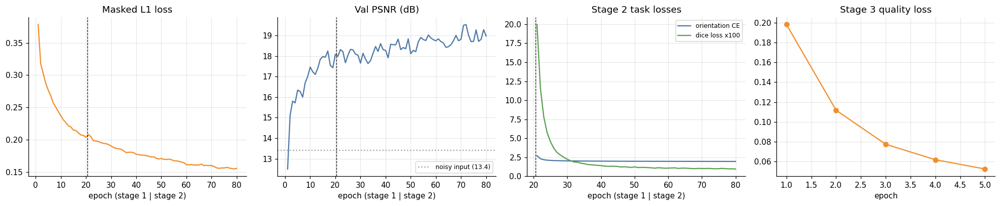

In [29]:
# Stage 1 (20 ep)
s1_L1 = [.3783,.3178,.3027,.2874,.2770,.2684,.2569,.2505,.2438,.2371,.2310,.2266,.2217,.2199,.2150,.2143,.2107,.2075,.2068,.2037]
s1_ps = [12.50,15.11,15.80,15.72,16.34,16.27,16.00,16.70,17.00,17.46,17.23,17.10,17.40,17.84,17.97,17.94,18.24,17.54,17.43,18.08]
# Stage 2 (60 ep)
s2_L1 = [.2081,.2047,.1984,.1981,.1973,.1955,.1945,.1939,.1927,.1905,.1880,.1868,.1860,.1854,.1830,.1803,.1807,.1808,.1800,.1777,
         .1770,.1764,.1762,.1754,.1746,.1734,.1736,.1714,.1703,.1712,.1697,.1695,.1701,.1693,.1675,.1674,.1667,.1657,.1645,.1615,
         .1612,.1619,.1608,.1610,.1611,.1623,.1600,.1604,.1602,.1602,.1587,.1566,.1558,.1565,.1564,.1573,.1564,.1556,.1548,.1559]
s2_ori = [2.6946,2.2958,2.1667,2.1052,2.0747,2.0507,2.0401,2.0282,2.0198,2.0113,2.0051,1.9995,1.9946,1.9923,1.9859,1.9882,1.9810,1.9800,1.9798,1.9739,
          1.9724,1.9685,1.9666,1.9683,1.9655,1.9629,1.9622,1.9613,1.9576,1.9586,1.9580,1.9557,1.9568,1.9575,1.9525,1.9510,1.9543,1.9507,1.9489,1.9496,
          1.9501,1.9466,1.9446,1.9443,1.9453,1.9453,1.9436,1.9410,1.9450,1.9413,1.9412,1.9379,1.9395,1.9408,1.9390,1.9401,1.9374,1.9350,1.9364,1.9367]
s2_seg = [.1997,.1161,.0782,.0573,.0454,.0366,.0309,.0276,.0247,.0222,.0203,.0186,.0185,.0171,.0164,.0154,.0150,.0147,.0142,.0139,
          .0132,.0129,.0131,.0130,.0127,.0120,.0124,.0119,.0115,.0122,.0113,.0115,.0115,.0112,.0110,.0105,.0111,.0108,.0105,.0106,
          .0108,.0109,.0102,.0106,.0106,.0103,.0100,.0099,.0102,.0100,.0100,.0102,.0099,.0097,.0099,.0102,.0099,.0096,.0097,.0094]
s2_ps  = [17.98,18.31,18.21,17.67,18.03,18.32,18.30,18.09,18.04,17.65,18.13,17.85,17.63,17.77,18.13,18.46,18.22,18.60,18.31,18.27,
          17.91,18.57,18.55,18.54,18.82,18.31,18.41,18.35,18.83,18.11,18.27,18.21,18.69,18.90,18.80,18.75,19.02,18.88,18.79,18.74,
          18.83,18.70,18.63,18.42,18.45,18.55,18.74,19.00,18.74,18.81,19.49,19.53,19.01,18.70,18.71,19.27,18.71,18.81,19.28,18.97]
# Stage 3 (5 ep)
q3 = [.1983, .1117, .0773, .0617, .0523]

h12 = pd.DataFrame({"stage": [1]*20 + [2]*60, "L1": s1_L1 + s2_L1, "psnr": s1_ps + s2_ps,
                    "ori": [np.nan]*20 + s2_ori, "seg": [np.nan]*20 + s2_seg})
h12["g"] = np.arange(1, len(h12) + 1)
h3 = pd.DataFrame({"ep": range(1, 6), "qua": q3})
n1 = 20; s2 = h12[h12.stage == 2]

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
ax[0].plot(h12.g, h12.L1, c=C_R); ax[0].set_title("Masked L1 loss")
ax[1].plot(h12.g, h12.psnr, c=C_E); ax[1].axhline(13.4, ls=":", c=C_N, label="noisy input (13.4)")
ax[1].set_title("Val PSNR (dB)"); ax[1].legend(fontsize=8)
ax[2].plot(s2.g, s2.ori, label="orientation CE", c=C_E); ax[2].plot(s2.g, s2.seg * 100, label="dice loss x100", c=C_C)
ax[2].set_title("Stage 2 task losses"); ax[2].legend(fontsize=8)
ax[3].plot(h3.ep, h3.qua, marker="o", c=C_R); ax[3].set_title("Stage 3 quality loss")
for a in ax[:3]: a.axvline(n1 + .5, ls="--", c="k", lw=.8); a.set_xlabel("epoch (stage 1 | stage 2)")
ax[3].set_xlabel("epoch")
save(fig, "9_training_curves")

                   key device  nfiq2_noisy  nfiq2_enhQ  nfiq2_clean
00002383_R_500_slap_06      R         42.0        85.0         91.0
00002443_U_500_roll_01      U          3.0        77.0         91.0
00002443_U_500_roll_06      U         21.0        80.0         91.0


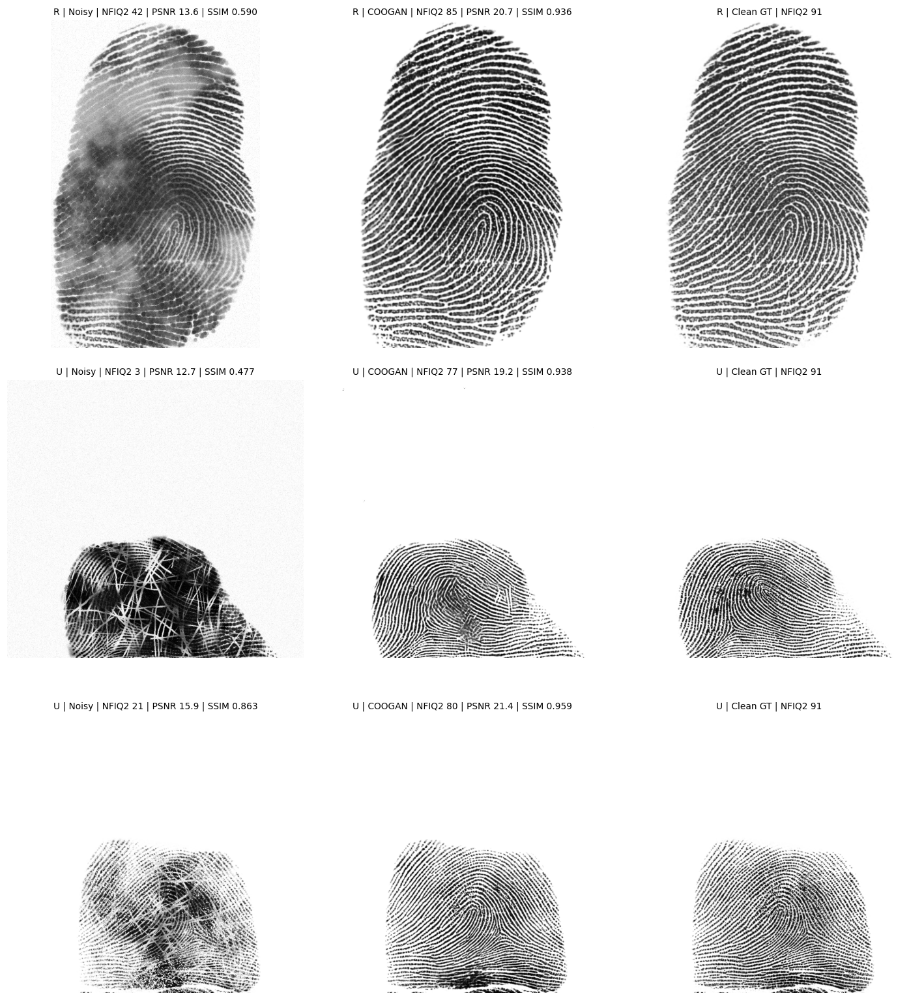

In [30]:
import matplotlib.pyplot as plt

TOPN = 3
SORT_BY = "nfiq2_clean"   # "nfiq2_enhQ" ya "nfiq2_noisy" bhi try kar sakti ho
VAR = "enh_q"             # "enh" = raw output, "enh_q" = mask ke saath (full COOGAN)

sfx = "enhQ" if VAR == "enh_q" else "enh"
top = res.sort_values(SORT_BY, ascending=False).head(TOPN)
print(top[["key", "device", "nfiq2_noisy", f"nfiq2_{sfx}", "nfiq2_clean"]].round(1).to_string(index=False))

fig, ax = plt.subplots(TOPN, 3, figsize=(13, 4.8 * TOPN))
for i, (_, r) in enumerate(top.iterrows()):
    n = cv2.imread(f"{NOISY_DIR}/{r.device}/{r.key}.png", 0)
    e = cv2.imread(f"{OUT_DIR}/{VAR}/{r.key}.png", 0)
    c = cv2.imread(f"{CLEAN_DIR}/{r.device}/{r.key}.png", 0)
    items = [(n, f"Noisy | NFIQ2 {r.nfiq2_noisy:.0f} | PSNR {r.psnr_noisy:.1f} | SSIM {r.ssim_noisy:.3f}"),
             (e, f"COOGAN | NFIQ2 {r[f'nfiq2_{sfx}']:.0f} | PSNR {r[f'psnr_{sfx}']:.1f} | SSIM {r[f'ssim_{sfx}']:.3f}"),
             (c, f"Clean GT | NFIQ2 {r.nfiq2_clean:.0f}")]
    for a, (im, t) in zip(ax[i], items):
        a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(f"{r.device} | {t}", fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

In [35]:
import zipfile
import os

base_path = "/kaggle/working"
zip_file = "/kaggle/working/coogan_backup.zip"

folders = [
    "coogan_graphs",
    "checkpoints",
    "coogan_test_out"
]

with zipfile.ZipFile(zip_file, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for folder in folders:
        folder_path = os.path.join(base_path, folder)

        for root, dirs, files in os.walk(folder_path):
            for file in files:
                file_path = os.path.join(root, file)

                arcname = os.path.relpath(file_path, base_path)
                zipf.write(file_path, arcname)

print("ZIP created successfully!")
print("Location:", zip_file)
print("Size:", round(os.path.getsize(zip_file) / (1024**3), 3), "GB")

ZIP created successfully!
Location: /kaggle/working/coogan_backup.zip
Size: 0.204 GB


In [36]:
import zipfile

with zipfile.ZipFile("/kaggle/working/coogan_backup.zip", "r") as zipf:
    for name in zipf.namelist():
        print(name)

coogan_graphs/3_per_device.png
coogan_graphs/5_per_image_scatter.png
coogan_graphs/1_before_after.png
coogan_graphs/8_inference_time.png
coogan_graphs/9_training_curves.png
coogan_graphs/2_mask_ablation.png
coogan_graphs/6_model_comparison.png
coogan_graphs/10_fused_psnr_ssim.png
coogan_graphs/7_per_device_models.png
coogan_graphs/4_nfiq2_distribution.png
checkpoints/stage3_last.pt
checkpoints/stage1_last.pt
checkpoints/stage1_best.pt
checkpoints/stage2_last.pt
checkpoints/stage2_best.pt
checkpoints/stage3_best.pt
coogan_test_out/test_metrics_with_nfiq2.csv
coogan_test_out/test_metrics.csv
coogan_test_out/enh/00002462_R_500_slap_07.png
coogan_test_out/enh/00002303_V_500_roll_02.png
coogan_test_out/enh/00002557_S_500_slap_06.png
coogan_test_out/enh/00002405_V_500_roll_07.png
coogan_test_out/enh/00002555_V_500_roll_05.png
coogan_test_out/enh/00002443_U_500_roll_07.png
coogan_test_out/enh/00002630_U_500_roll_09.png
coogan_test_out/enh/00002375_U_500_roll_07.png
coogan_test_out/enh/0000243

In [37]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/coogan_backup.zip"))

/kaggle/working/coogan_backup.zip